In [1]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
import matplotlib.pyplot as plt

from utils import view_image, load_cifar10_dataset, remove_module_prefix 

from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from mnist_denoising_diffusion_model_implementation import DiffusionModel


import matplotlib.pyplot as plt
import numpy as np

from torchmetrics.image.fid import FrechetInceptionDistance

In [11]:
def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)

    return data

def process_image(image):
    image = (image - image.min()) / (image.max() - image.min())  # Normalize to [0, 1]
    image = (image * 255).clamp(0, 255).byte()  # Scale to [0, 255] and convert to uint8
    return image

In [3]:
trainY, testY = load_cifar10_dataset(root='/workspace/aim-bridges-data/cifar10', download=True)

Files already downloaded and verified
Files already downloaded and verified


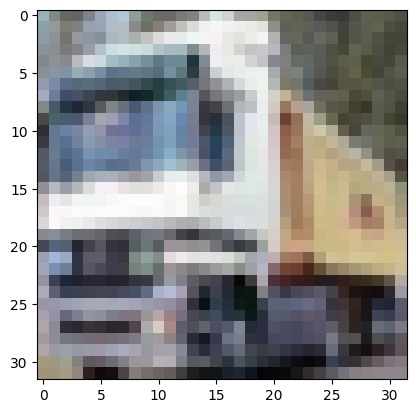

In [4]:
plt.imshow(trainY[1].permute(1, 2, 0))

In [39]:
model = UNet(in_ch=3)
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_38000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_38000.pth'


<All keys matched successfully>

In [59]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Total number of trainable parameters: {count_parameters(model)}')

Total number of trainable parameters: 35717891


  0%|          | 0/1000 [00:00<?, ?it/s]/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
100%|██████████| 1000/1000 [00:33<00:00, 29.88it/s]


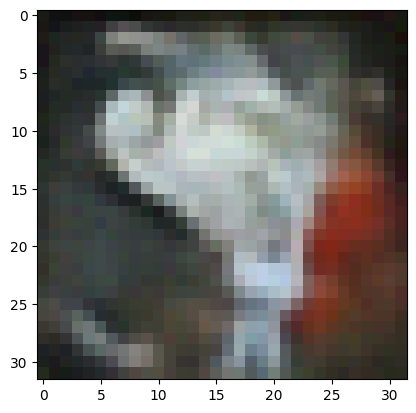

In [54]:
T = 0.1
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)
samples = diffusion_model.sampling(n_samples=50, image_channels=3, use_tqdm=True, n_steps=1000)
plt.imshow(samples.cpu()[0].permute(1, 2, 0))

In [55]:
test_sample = sample_batch(trainY=testY, batch_size=100, device='cuda')

In [56]:
fid = FrechetInceptionDistance().to('cuda')


In [57]:
train_sample_int  = torch.stack([process_image(samp) for samp in test_sample])
model_sample_int = torch.stack([process_image(samp) for samp in samples])
fid.update(train_sample_int, real=True)
fid.update(model_sample_int, real=False)

In [58]:
fid.compute()

tensor(247.1761, device='cuda:0')